# **Module 01: Types of Variables, Measurement Scales, and Precision**

---

## 📌 Overview

Before applying any statistical technique, building a chart, or training a Machine Learning model, it is essential to understand the nature of the data collected. Most analytical mistakes start at the very beginning: treating a variable as if it possessed mathematical properties that it does not actually have.

In this notebook, we will establish the conceptual foundation for classifying variables, identifying their measurement scales, and evaluating the quality and reliability of measurements.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Classify variables accurately** into qualitative (nominal and ordinal) and quantitative (discrete and continuous) types.
* **Identify the four measurement scales** (nominal, ordinal, interval, and ratio) and determine which mathematical and statistical operations are valid for each.
* **Distinguish between precision and accuracy**, recognizing the impact of systematic errors (bias) and random errors (noise) on data quality.
* **Evaluate measurement quality** using the concepts of validity and reliability.
* **Avoid common practical pitfalls**, such as performing arithmetic on numeric codes, misinterpreting ordinal scales, or reporting false precision.

---

## 🧭 Module Structure

1. **Types of Variables** — Qualitative (nominal, ordinal) and quantitative (discrete, continuous) classifications.
2. **Measurement Scales** — Nominal, ordinal, interval, and ratio levels, and their permitted operations.
3. **Precision, Accuracy, and Measurement Errors** — Bias vs. noise, validity, and reliability.
4. **Common Practical Pitfalls** — Numeric identifiers, ordinal arithmetic, and false precision.
5. **Hands-on Python** — Inspecting, converting, and validating variable data types using `pandas` and `numpy`.

---

## 🛠️ Technical Requirements

* Basic familiarity with Python syntax.
* Python environment configured with: `numpy` and `pandas`.

## Python Virtual Environment Setup

### 1. Create the virtual environment

```bash
python3 -m venv .venv
```

### 2. Activate the virtual environment
Linux / macOS:

```bash
source .venv/bin/activate
```

Windows (PowerShell):

```PowerShell
.\.venv\Scripts\Activate.ps1
```
Windows (Command Prompt):

```DOS
.venv\Scripts\activate.bat
```

### 3. Upgrade pip and install dependencies (optional)
```bash
pip install --upgrade pip
pip install -r requirements.txt
```

### 4. Deactivate the virtual environment
```bash
deactivate
```

In [2]:
# First, we need to install the required libraries
%pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib as plt
import math

## 1. Types of Variables

A **variable** is any characteristic, attribute, or quantity observed across a set of elements (people, sensors, transactions, municipalities) that can take on different values from one observation to another.

Broadly speaking, variables are divided into two main groups: **qualitative** (categorical) and **quantitative** (numerical).

### 1.1 Qualitative (Categorical) Variables

They express attributes, labels, or qualities that do not represent a measurable physical quantity.

* **Nominal Qualitative:** values serve solely to name or categorize groups, with no order or hierarchy between them.
  * *Examples:* operating system (`Linux`, `Windows`, `macOS`), payment method (`Pix`, `Card`, `Bank Slip`), marital status.
* **Ordinal Qualitative:** in addition to categorizing, there is a natural ordering among the classes, although the exact distance between one level and another is not measurable.
  * *Examples:* education level (`Elementary`, `High School`, `Undergraduate`), ticket priority (`Low`, `Medium`, `High`, `Critical`), satisfaction rating scale.

### 1.2 Quantitative (Numerical) Variables

They represent counts or measurements expressed as real numbers, allowing meaningful arithmetic operations.

* **Discrete Quantitative:** generally results from a counting process and assumes isolated values (finite or countable), with no valid intermediate values between two consecutive numbers.
  * *Examples:* number of requests per minute, number of children, total errors recorded in a log.
* **Continuous Quantitative:** results from a measurement process and can take any value within a real interval, limited only by the precision of the measuring instrument.
  * *Examples:* server latency time (in milliseconds), ambient temperature, cargo weight, distance traveled.

### Summary Table and Mapping for Data Science

| Classification | Subtype | Practical Example | Typical Representation (Python/Pandas) |
| :--- | :--- | :--- | :--- |
| **Qualitative** | Nominal | Product category | `object` / `category` (unordered) |
| **Qualitative** | Ordinal | Risk level (Low, Medium, High) | `category` (`ordered=True`) |
| **Quantitative** | Discrete | Number of items in cart | `int64` |
| **Quantitative** | Continuous | Response time in seconds | `float64` |

* `Non-metric variables:` also called categorical or qualitative, they represent characteristics of individuals that cannot be measured, only classified.
* `Metric variables:` also called quantitative, they represent characteristics of individuals that result from counts or measurements.

## **Non-Metric Variables**

In [4]:
# Creating data
salary_classes = [
    ['A', 'Above 20 MW', 'Above R$ 15760.00'],
    ['B', '10 to 20 MW', 'From R$ 7880.00 to R$ 15760.00'],
    ['C', '4 to 10 MW', 'From R$ 3152.00 to R$ 7880.00'],
    ['D', '2 to 4 MW', 'From R$ 1576.00 to R$ 3152.00'],
    ['E', 'Up to 2 MW', 'Up to R$ 1576.00']
]

columns = ['Class', 'Minimum Wage (MW)', 'Family Income (FI)']

In [5]:
# Displaying the DataFrame
salary_classes_df = pd.DataFrame(salary_classes)
salary_classes_df.columns = columns
salary_classes_df

,Class,Minimum Wage (MW),Family Income (FI)
0,A,Above 20 MW,Above R$ 15760.00
1,B,10 to 20 MW,From R$ 7880.00 to R$ 15760.00
2,C,4 to 10 MW,From R$ 3152.00 to R$ 7880.00
3,D,2 to 4 MW,From R$ 1576.00 to R$ 3152.00
4,E,Up to 2 MW,Up to R$ 1576.00


Note that the data are divided into ranges, making them qualitative. In this case, we can calculate frequencies, but not summary measures such as the mean and standard deviation.

`NOTE:` *Be careful when using the numerical information in these ranges; do not treat them as quantitative data.*

We can, for example, see how often each class occurs—that is, the frequency of each class.

In [6]:
salary_classes_df["Frequency"] = ["10%", "18%", "24%", "36%", "12%"]
salary_classes_df

,Class,Minimum Wage (MW),Family Income (FI),Frequency
0,A,Above 20 MW,Above R$ 15760.00,10%
1,B,10 to 20 MW,From R$ 7880.00 to R$ 15760.00,18%
2,C,4 to 10 MW,From R$ 3152.00 to R$ 7880.00,24%
3,D,2 to 4 MW,From R$ 1576.00 to R$ 3152.00,36%
4,E,Up to 2 MW,Up to R$ 1576.00,12%


## **Metric Variables**

Quantitative variables can be represented by line charts, scatter plots, histograms, etc., and summarized by measures of position (mean, median, mode, quartiles, etc.) and dispersion (range, deviations, variance, etc.).

In [7]:
# Creating data
data = [
    ['João', 48, 5000, 4, 2000, 'Brazil', 'D'],
    ['Maria', 23, 1500, 1, 5000, 'Argentina', 'C'],
    ['José', 47, 9000, 10, 9000, 'Brazil', 'C'],
    ['Frank', 19, 400, 0, 3000, 'Morocco', 'D'],
    ['Mario', 33, 3400, 3, 3400, 'Germany', 'D']
]

columns = ['Name', 'Age', 'Salary', 'Years of Experience', 'Family Income', 'Country of Origin', 'Class']

In [8]:
df = pd.DataFrame(data)
df.columns = columns
df

,Name,Age,Salary,Years of Experience,Family Income,Country of Origin,Class
0,João,48,5000,4,2000,Brazil,D
1,Maria,23,1500,1,5000,Argentina,C
2,José,47,9000,10,9000,Brazil,C
3,Frank,19,400,0,3000,Morocco,D
4,Mario,33,3400,3,3400,Germany,D


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Name                 5 non-null      str  
 1   Age                  5 non-null      int64
 2   Salary               5 non-null      int64
 3   Years of Experience  5 non-null      int64
 4   Family Income        5 non-null      int64
 5   Country of Origin    5 non-null      str  
 6   Class                5 non-null      str  
dtypes: int64(4), str(3)
memory usage: 412.0 bytes


Note that the only textual variables are the person's name, country of origin, and class, which are qualitative: `Name` and `Country of Origin` are on a nominal scale, and `Class` is on an ordinal scale. The remaining variables are quantitative, resulting from counts or measurements.

## **Types of Variables vs. Measurement Scales**

`Measurement:` the process of assigning numbers or labels to objects of study, based on specific rules, to represent the quantities or qualities of their attributes.

`Rule:` a guide, method, or command that indicates how to measure the attribute.

`Scale:` a set of symbols or numbers constructed based on the rule and applied to each object.

* `Qualitative variables` $\rightarrow$ nominal or ordinal scale
* `Quantitative variables` $\rightarrow$ interval or ratio scale

### **Nominal Scale**
Non-metric variables

On this scale, categories do not establish any magnitude or order, being differentiated solely by their names.

We can assign numeric labels to categories, but arithmetic operations on them make no sense. It is possible to count the number of elements in each class, calculate the mode, and apply hypothesis tests designed for categorical data.

*Examples: profession, religion, color, marital status, geographic location.*

`NOTE:` *Most statistics, such as the mean and standard deviation, are meaningless for nominal data.*

We can, for example, use numeric labels to represent each category and make them easier to identify.

In [10]:
# Representation using numeric labels
nominal_rep = {"Brazil": 12, "Argentina": 25, "Morocco": 32, "Germany": 45}
df["Label"] = df["Country of Origin"].map(nominal_rep)
df

,Name,Age,Salary,Years of Experience,Family Income,Country of Origin,Class,Label
0,João,48,5000,4,2000,Brazil,D,12
1,Maria,23,1500,1,5000,Argentina,C,25
2,José,47,9000,10,9000,Brazil,C,12
3,Frank,19,400,0,3000,Morocco,D,32
4,Mario,33,3400,3,3400,Germany,D,45


Nominal scale labels are arbitrarily assigned to categories. From them, we can describe the data using frequency distribution tables, bar or pie charts, and by calculating the mode.

In [11]:
country_count = pd.DataFrame(df.iloc[:, [5, 7]].value_counts())
country_count

,,count
Country of Origin,Label,
Brazil,12,2
Argentina,25,1
Morocco,32,1
Germany,45,1


From this count, we can identify which country of origin appears most frequently among the people listed.

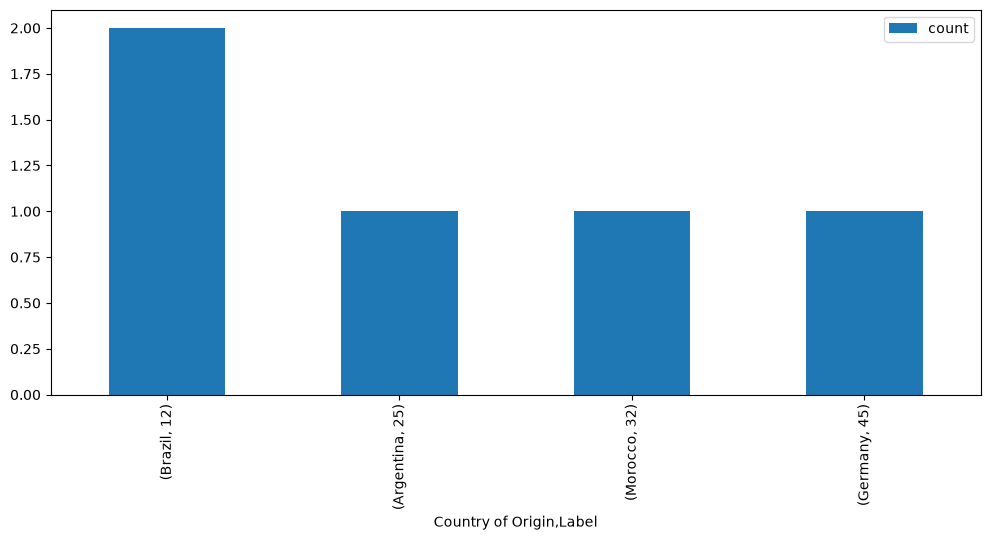

In [12]:
country_count.plot(kind="bar", figsize=(12, 5));

### **Ordinal Scale**
Non-metric variables

Basically, it is a categorical variable whose classes have a relative position following an order. Just like on the nominal scale, arithmetic operations do not make sense, and descriptive statistics are limited to frequency distribution tables, charts, the mode, and position measures such as the median.

*Examples: opinion scale, preference scale, education level, social class, age group...*

In [13]:
scale_values = pd.DataFrame([
    [1, "Very Poor"],
    [2, "Poor"],
    [3, "Fair"],
    [4, "Good"],
    [5, "Very Good"]
])

scale_values.columns = ["Value", "Label"]
scale_values

,Value,Label
0,1,Very Poor
1,2,Poor
2,3,Fair
3,4,Good
4,5,Very Good


Instead of a 1-to-5 scale, any other numerical scale could be used, as long as the order of the classification is preserved.

In [14]:
salary_classes_df

,Class,Minimum Wage (MW),Family Income (FI),Frequency
0,A,Above 20 MW,Above R$ 15760.00,10%
1,B,10 to 20 MW,From R$ 7880.00 to R$ 15760.00,18%
2,C,4 to 10 MW,From R$ 3152.00 to R$ 7880.00,24%
3,D,2 to 4 MW,From R$ 1576.00 to R$ 3152.00,36%
4,E,Up to 2 MW,Up to R$ 1576.00,12%


In [15]:
class_count = df["Class"].value_counts().reset_index()
class_count.columns = ["Class", "People"]
class_count = pd.merge(salary_classes_df, class_count, how="left", on=["Class"])
class_count = class_count[class_count["People"] > 0]
class_count

,Class,Minimum Wage (MW),Family Income (FI),Frequency,People
2,C,4 to 10 MW,From R$ 3152.00 to R$ 7880.00,24%,2.0
3,D,2 to 4 MW,From R$ 1576.00 to R$ 3152.00,36%,3.0


### **Interval Scale**
Quantitative variables

Basically, these are metric variables that, in addition to ordering units according to the measured characteristic, have a constant unit of measurement. However, the origin (zero) is arbitrary and does not indicate the absence of the quantity, as in temperature measured in °C and °F.

The interval scale is invariant under positive linear transformations, meaning one scale can be converted into another through a linear transformation, such as from °F to °C.

`NOTE:` *Lengths (cm, m, km) are also converted by linear transformations, but since they have an absolute zero, they belong to the ratio scale.*

In [16]:
# Convert centimeters to meters
def convert_cm_to_m(measurement):
    return print(f"{measurement * 0.01} m")

In [17]:
convert_cm_to_m(100)

1.0 m


In [18]:
# Convert Fahrenheit to Celsius
def convert_f_to_c(measurement):
    return print(f"{np.round((measurement - 32) * 5/9, 2)} °C")

In [19]:
convert_f_to_c(10)

-12.22 °C


### **Ratio Scale**
Quantitative variables

This scale is analogous to the interval scale: it orders units with respect to the measured characteristic and has a constant unit of measurement. The difference is that the origin is unique and the value zero represents the complete absence of the quantity.

Therefore, ratios between values are meaningful: if one object measures 1 meter and another measures 3 meters, the second is 3 times the length of the first.

*Examples: income, age, quantity produced of a given product, distance traveled.*

In [20]:
joao = df[df["Name"] == "João"]
jose = df[df["Name"] == "José"]

In [21]:
# Salary ratio
salary_joao = joao["Salary"].iloc[0]
salary_jose = jose["Salary"].iloc[0]

print(f"João's salary is R$ {salary_joao}")
print(f"José's salary is R$ {salary_jose}")

print(f"The salary difference between João and José is: R$ {salary_joao - salary_jose}")
print(f"João's salary is equivalent to {np.round(salary_joao / salary_jose * 100, 2)}% of José's salary")
print(f"João earns {np.round((1 - salary_joao / salary_jose) * 100, 2)}% less than José")

João's salary is R$ 5000
José's salary is R$ 9000
The salary difference between João and José is: R$ -4000
João's salary is equivalent to 55.56% of José's salary
João earns 44.44% less than José


## **Types of Variables vs. Number of Categories and Precision Scale**

* `Categorical` $\rightarrow$ dichotomous/binary or polychotomous
* `Metric` $\rightarrow$ discrete or continuous

### **Dichotomous or Binary Variable (Dummy)**
Non-metric variables

This type of variable takes only two categories, where `0` indicates the absence and `1` indicates the presence of the characteristic.

*Example: smoker (1) and non-smoker (0)*

In [22]:
df_dummy = pd.get_dummies(df, columns=["Class"], dtype=int)
df_dummy["Class_A"] = 0
df_dummy["Class_B"] = 0
df_dummy["Class_E"] = 0
df_dummy[["Name", "Class_C", "Class_D", "Class_A", "Class_B", "Class_E"]]

,Name,Class_C,Class_D,Class_A,Class_B,Class_E
0,João,0,1,0,0,0
1,Maria,1,0,0,0,0
2,José,1,0,0,0,0
3,Frank,0,1,0,0,0
4,Mario,0,1,0,0,0


### **Polychotomous Variable**
Non-metric variables

In this case, the variable can take more than two categories.

*Example: low income (1), middle income (2), high income (3)*

In [23]:
new_data = {
    "Name": "Manoel", "Age": 33, "Salary": 1200, "Years of Experience": 1,
    "Family Income": 1200, "Country of Origin": "Brazil", "Class": "E"
}

# Adding new record to the DataFrame
df = pd.concat([df, pd.DataFrame([new_data])], ignore_index=True)
df

,Name,Age,Salary,Years of Experience,Family Income,Country of Origin,Class,Label
0,João,48,5000,4,2000,Brazil,D,12.0
1,Maria,23,1500,1,5000,Argentina,C,25.0
2,José,47,9000,10,9000,Brazil,C,12.0
3,Frank,19,400,0,3000,Morocco,D,32.0
4,Mario,33,3400,3,3400,Germany,D,45.0
5,Manoel,33,1200,1,1200,Brazil,E,NaN


In [24]:
# Creating numeric codes for multiple classes
df["Label"] = df.Class.astype("category").cat.codes
df[["Name", "Class", "Label"]]

,Name,Class,Label
0,João,D,1
1,Maria,C,0
2,José,C,0
3,Frank,D,1
4,Mario,D,1
5,Manoel,E,2


### **Discrete Variables**
Metric variables

They take a finite or countable set of values, generally resulting from counts.

*Example: number of children*

In [25]:
new_children_data = [0, 2, 1, 0, 3, 0]

# Adding new column to the DataFrame
df["Children"] = new_children_data
df[["Name", "Children"]]

,Name,Children
0,João,0
1,Maria,2
2,José,1
3,Frank,0
4,Mario,3
5,Manoel,0


### **Continuous Variables**
Metric variables

These are variables whose possible values belong to an interval of real numbers ($\in \mathbb{R}$) and result from a measurement.

*Examples: weight, height, salary...*

In [26]:
df[["Name", "Salary"]]

,Name,Salary
0,João,5000
1,Maria,1500
2,José,9000
3,Frank,400
4,Mario,3400
5,Manoel,1200


## Supporting Bibliographical References
![Favero, Belfiore](./imgs/f7c5f9e2-192e-47a1-8e8c-72bad326ad1b.png)
* FÁVERO, Luiz Paulo; BELFIORE, Patrícia. **Manual de análise de dados**: estatística e modelagem multivariada com Excel®, SPSS® e Stata®. 1st ed. Rio de Janeiro: LTC, 2017.

![Netto, Maciel](./imgs/958ebd9f-7733-4a45-9220-4cc27cd07506.png)
* NETTO, Amilcar; MACIEL, Francisco. **Python para Data Science e Machine Learning descomplicado**. Rio de Janeiro: Alta Books, 2021.

![Wheelan](./imgs/06a77678-77e0-483c-9b5d-8ba2084d31c2.png)
* WHEELAN, Charles. **Naked Statistics**: Stripping the Dread from the Data. New York: W. W. Norton & Company, 2013. (Brazilian Portuguese edition: *Estatística: o que é, para que serve, como funciona*, Rio de Janeiro: Zahar, 2016.)